# Object Detection: Where Is Each Pedestrian?

This notebook goes with the lecture on object detection. Lecture 16's network labeled every pixel "person" or "background", and could not tell two overlapping pedestrians apart. A detector returns **one box per object**, each with a class label and a confidence score.

1. A pretrained **Faster R-CNN** from `torchvision`, and what it returns.
2. **Intersection over union (IoU)** for boxes, written by hand.
3. **Non-max suppression (NMS)**, written by hand, on the detector's raw output.
4. The two stages of Faster R-CNN, counted: anchors, proposals, detections.
5. Scoring a detector: precision, recall and **average precision (AP)**, by hand.
6. Adapting the detector to our own classes (Lecture 15's recipe: replace the head, fine-tune).
7. From boxes to masks: **Mask R-CNN**, and the two pedestrians that Lecture 16 could not separate.

The data is the **Penn-Fudan** pedestrian dataset of Lecture 16's notebook, with the same 120 training and 50 test photos. The code downloads it (51 MB) into `data/PennFudanPed/` if it is not there yet, and the pretrained weights (160 MB and 170 MB) into PyTorch's cache.

Running time: about 5 minutes with a GPU. Without a GPU the fine-tuning step is skipped (it would take most of an hour) and the rest takes about 5 minutes.

In [1]:
import time
import urllib.request
import zipfile
from pathlib import Path

import cv2 as cv
import numpy as np
import torch
from matplotlib import pyplot as plt
from torchvision import models, ops
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

# A GPU if there is one: NVIDIA (cuda), otherwise the CPU (detection models do not run reliably on Apple's mps yet)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)

device: cuda


## The Data: Boxes from Masks

Every photo comes with a mask in which 0 is background and 1, 2, 3, ... number the pedestrians. Lecture 16 used `mask > 0`. Here we keep the pedestrians apart and turn each one into a **box**: the smallest rectangle that contains all of its pixels.

A box is four numbers, **(x1, y1, x2, y2)**: its left, top, right and bottom edges, in pixels. This is the format `torchvision` uses. (The lecture's slides also use (x, y, w, h): a corner plus width and height. Always check which one a library expects.)

In [2]:
root = Path('data/PennFudanPed')
if not root.exists():
    root.parent.mkdir(exist_ok=True)
    archive = root.parent / 'PennFudanPed.zip'
    urllib.request.urlretrieve('https://www.cis.upenn.edu/~jshi/ped_html/PennFudanPed.zip', archive)
    with zipfile.ZipFile(archive) as z:
        z.extractall(root.parent)
    archive.unlink()

files = sorted((root / 'PNGImages').glob('*.png'))

def read_photo(i):
    return cv.cvtColor(cv.imread(str(files[i])), cv.COLOR_BGR2RGB)      # OpenCV reads BGR

def read_mask(i):
    return cv.imread(str(root / 'PedMasks' / (files[i].stem + '_mask.png')), cv.IMREAD_GRAYSCALE)

def true_boxes(i):
    mask = read_mask(i)
    boxes = []
    for person in np.unique(mask)[1:]:                # 1, 2, 3, ...: one pedestrian each
        rows, cols = np.where(mask == person)
        boxes.append([cols.min(), rows.min(), cols.max() + 1, rows.max() + 1])
    return torch.tensor(boxes, dtype=torch.float32)   # (number of pedestrians, 4): x1, y1, x2, y2

def to_tensor(rgb):
    return torch.from_numpy(rgb).permute(2, 0, 1).float() / 255         # (3, H, W), values 0 to 1

order = torch.randperm(len(files), generator=torch.Generator().manual_seed(0))   # the split of Lecture 16's notebook
train_idx, test_idx = order[:120].tolist(), order[120:].tolist()
print(len(files), 'photos:', len(train_idx), 'for training,', len(test_idx), 'for testing')
print('pedestrians in the test photos:', sum(len(true_boxes(i)) for i in test_idx))
print(f'RESULT test_people: {sum(len(true_boxes(i)) for i in test_idx)}')

170 photos: 120 for training, 50 for testing


pedestrians in the test photos: 133


RESULT test_people: 133


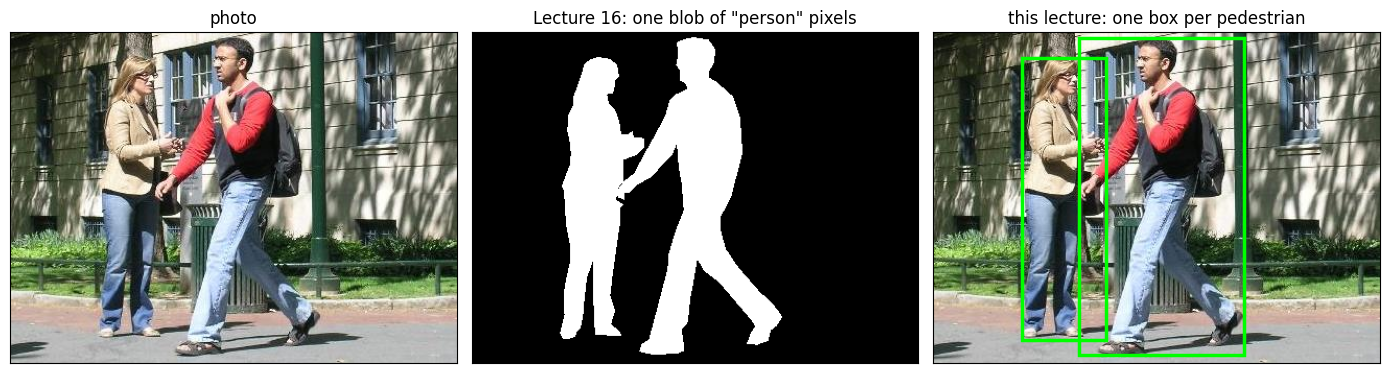

tensor([[ 84.,  24., 165., 294.],
        [139.,   5., 297., 309.]])


In [3]:
def draw_boxes(ax, boxes, color, labels=None, width=2.5, style='-'):
    for k, (x1, y1, x2, y2) in enumerate(boxes.tolist()):
        ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=color, linewidth=width, linestyle=style))
        if labels is not None:
            ax.text(x1, y1 - 4, labels[k], color='white', fontsize=10, bbox=dict(facecolor=color, edgecolor='none', pad=1.5))

TWO = 162                                             # the photo that ended Lecture 16: two overlapping pedestrians
fig, axs = plt.subplots(1, 3, figsize=(14, 4.4))
axs[0].imshow(read_photo(TWO)); axs[0].set_title('photo')
axs[1].imshow(read_mask(TWO) > 0, cmap='gray'); axs[1].set_title('Lecture 16: one blob of "person" pixels')
axs[2].imshow(read_photo(TWO)); draw_boxes(axs[2], true_boxes(TWO), 'lime'); axs[2].set_title('this lecture: one box per pedestrian')
for ax in axs:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()
print(true_boxes(TWO))

## A Pretrained Detector

`fasterrcnn_resnet50_fpn` is a Faster R-CNN with a ResNet-50 backbone, trained on the COCO dataset: 118,000 photos with boxes for 80 kinds of everyday objects. The weights' category list has 91 entries because some numbers are unused.

Unlike a classifier, the model takes a **list** of images (they may have different sizes; it resizes them itself, so the shorter side is 800 pixels) and returns, for each image, a dictionary with three tensors of equal length: `boxes`, `labels` and `scores`.

In [4]:
weights = models.detection.FasterRCNN_ResNet50_FPN_Weights.DEFAULT
detector = models.detection.fasterrcnn_resnet50_fpn(weights=weights).eval().to(device)
categories = weights.meta['categories']
print(len(categories), 'category slots:', ', '.join(categories[1:9]), '...')

x = to_tensor(read_photo(TWO)).to(device)
with torch.no_grad():
    output = detector([x])[0]
for key, value in output.items():
    print(f'{key:7s} {tuple(value.shape)}')
print()
for box, label, score in zip(output['boxes'].tolist(), output['labels'].tolist(), output['scores'].tolist()):
    print(f'{categories[label]:10s} score {score:.2f}   box ({box[0]:5.0f}, {box[1]:5.0f}, {box[2]:5.0f}, {box[3]:5.0f})')

91 category slots: person, bicycle, car, motorcycle, airplane, bus, train, truck ...


boxes   (21, 4)
labels  (21,)
scores  (21,)

person     score 1.00   box (   83,    19,   170,   296)
person     score 1.00   box (  145,    14,   300,   303)
backpack   score 0.92   box (  246,    69,   280,   162)
backpack   score 0.73   box (  205,    58,   279,   156)
handbag    score 0.26   box (  210,    58,   284,   157)
handbag    score 0.23   box (  249,    69,   278,   158)
person     score 0.22   box (  107,    16,   218,   285)
bench      score 0.22   box (  275,   227,   316,   250)
backpack   score 0.19   box (  230,    26,   288,   143)
bench      score 0.11   box (    6,   211,    87,   251)
handbag    score 0.11   box (  141,    57,   210,   169)
person     score 0.10   box (  235,    23,   293,   257)
tie        score 0.09   box (  220,    61,   227,    79)
handbag    score 0.08   box (  231,    27,   287,   144)
handbag    score 0.08   box (  144,   150,   164,   177)
cell phone score 0.07   box (  209,    53,   213,    62)
person     score 0.07   box (  237,     7, 

The list is sorted by score, and most of it is low-confidence guesses: the model returns everything above a score of 0.05 and leaves the decision to us. **Choosing a score threshold is part of using a detector.** Here are the detections above 0.8, and all of them.

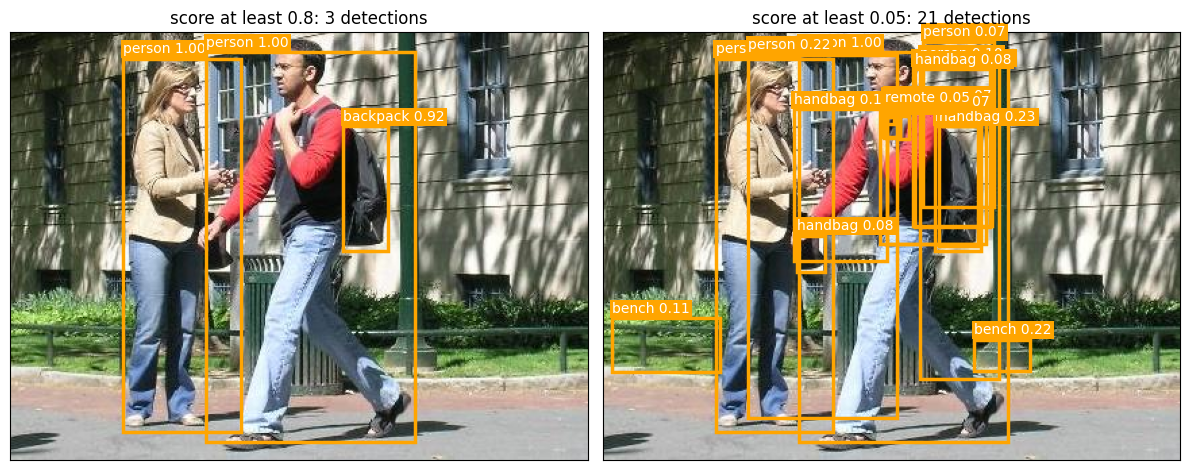

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, threshold in zip(axs, (0.8, 0.05)):
    keep = output['scores'] >= threshold
    ax.imshow(read_photo(TWO))
    draw_boxes(ax, output['boxes'][keep].cpu(), 'orange', [f'{categories[l]} {s:.2f}' for l, s in zip(output['labels'][keep].tolist(), output['scores'][keep].tolist())])
    ax.set_title(f'score at least {threshold}: {int(keep.sum())} detections')
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

## Comparing Boxes: Intersection over Union

Is a detected box "right"? It never matches the hand-drawn box exactly, so we measure overlap: the area the two boxes share, divided by the area they cover together. It is the IoU of Lecture 16, for rectangles instead of masks.

The intersection of two boxes is again a box: its left edge is the larger of the two left edges, its right edge the smaller of the two right edges, and likewise for top and bottom. If that leaves a negative width or height, the boxes do not overlap.

In [6]:
def area(box):
    return (box[2] - box[0]) * (box[3] - box[1])

def iou(a, b):
    x1, y1 = max(a[0], b[0]), max(a[1], b[1])
    x2, y2 = min(a[2], b[2]), min(a[3], b[3])
    intersection = max(0.0, x2 - x1) * max(0.0, y2 - y1)
    return intersection / (area(a) + area(b) - intersection)

truth = true_boxes(TWO)
best = output['boxes'][:2].cpu()                       # the two most confident detections
for d in best.tolist():
    print('detection', [round(v) for v in d], '  IoU with each true box:', [round(iou(d, t), 2) for t in truth.tolist()])
print('torchvision agrees:')
print(ops.box_iou(best, truth))

detection [83, 19, 170, 296]   IoU with each true box: [0.91, 0.14]
detection [145, 14, 300, 303]   IoU with each true box: [0.09, 0.9]
torchvision agrees:
tensor([[0.9059, 0.1372],
        [0.0876, 0.8976]])


The usual convention: a detection **matches** a true box if their IoU is at least 0.5. An IoU of 0.5 looks worse than it sounds, and 0.9 is nearly perfect.

## Non-Max Suppression

Internally the detector scores about a thousand candidate boxes, and many of them sit on the same person. The model removes those duplicates itself before returning. To see what it removes, we switch that step off (`nms_thresh = 1.0` means "never call two boxes duplicates") and look at the raw output for a street photo.

In [7]:
CROWD = 57
x = to_tensor(read_photo(CROWD)).to(device)
detector.roi_heads.nms_thresh, detector.roi_heads.detections_per_img = 1.0, 1000
with torch.no_grad():
    raw = detector([x])[0]
detector.roi_heads.nms_thresh, detector.roi_heads.detections_per_img = 0.5, 100       # back to the defaults
person = raw['labels'] == 1
raw_boxes, raw_scores = raw['boxes'][person].cpu(), raw['scores'][person].cpu()
print(len(raw_boxes), 'raw "person" boxes for', len(true_boxes(CROWD)), 'labeled pedestrians')
print(f'RESULT nms_raw: {len(raw_boxes)}')

252 raw "person" boxes for 8 labeled pedestrians
RESULT nms_raw: 252


**Non-max suppression** is a greedy loop:

1. take the remaining box with the highest score and keep it;
2. throw away every remaining box whose IoU with it is above a threshold (0.5 here);
3. repeat until no boxes remain.

252 boxes before, 24 after
same result as torchvision.ops.nms: True
9 of them have a score of at least 0.8
RESULT nms_kept: 24
RESULT nms_confident: 9


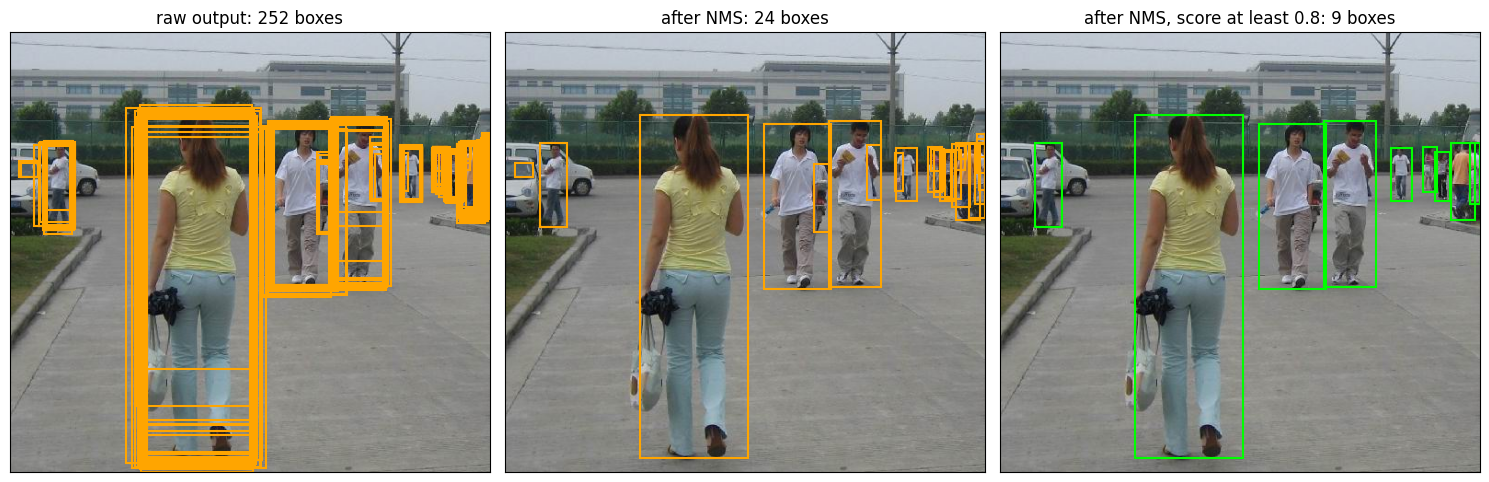

In [8]:
def nms(boxes, scores, threshold=0.5):
    remaining = scores.argsort(descending=True).tolist()      # box numbers, best first
    keep = []
    while remaining:
        best = remaining.pop(0)
        keep.append(best)
        remaining = [k for k in remaining if iou(boxes[best].tolist(), boxes[k].tolist()) <= threshold]
    return keep

keep = nms(raw_boxes, raw_scores)
print(len(raw_boxes), 'boxes before,', len(keep), 'after')
print('same result as torchvision.ops.nms:', keep == ops.nms(raw_boxes, raw_scores, 0.5).tolist())
confident = [k for k in keep if raw_scores[k] >= 0.8]
print(len(confident), 'of them have a score of at least 0.8')
print(f'RESULT nms_kept: {len(keep)}')
print(f'RESULT nms_confident: {len(confident)}')

fig, axs = plt.subplots(1, 3, figsize=(15, 4.9))
for ax, (title, idx, color) in zip(axs, ((f'raw output: {len(raw_boxes)} boxes', range(len(raw_boxes)), 'orange'), (f'after NMS: {len(keep)} boxes', keep, 'orange'),
                                         (f'after NMS, score at least 0.8: {len(confident)} boxes', confident, 'lime'))):
    ax.imshow(read_photo(CROWD)); draw_boxes(ax, raw_boxes[list(idx)], color, width=1.5)
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

NMS assumes that two boxes with a large overlap are the same object. In a crowd that is false: two people standing close together can have boxes with an IoU above 0.5, and NMS then deletes one of them. There is no clean fix, which is why crowded scenes stay hard for detectors.

## Two Stages, Counted

Faster R-CNN works in two stages. Stage 1, the **region proposal network (RPN)**, places **anchor boxes** of several sizes and shapes at every position of the feature maps and asks of each one: object or not? The best-scoring 1,000 become **proposals**. Stage 2 crops the features of each proposal, classifies it into one of the categories, and corrects its box.

We can watch the numbers shrink with *hooks*, small functions that PyTorch calls whenever a module has produced its output.

In [9]:
seen = {}
hooks = [detector.backbone.register_forward_hook(lambda module, inputs, out: seen.update(features={k: tuple(v.shape) for k, v in out.items()})),
         detector.rpn.anchor_generator.register_forward_hook(lambda module, inputs, out: seen.update(anchors=len(out[0]))),
         detector.rpn.register_forward_hook(lambda module, inputs, out: seen.update(proposals=len(out[0][0])))]
with torch.no_grad():
    final = detector([x])[0]
for h in hooks:
    h.remove()

print('photo:', tuple(x.shape), '(resized inside the model so that its shorter side is 800 pixels)')
print('feature maps from the backbone (a feature pyramid: the same 256 channels at five sizes):')
for name, shape in seen['features'].items():
    print(f'   {name:5s} {shape}')
print(f'anchors scored by stage 1:      {seen["anchors"]:,}   (3 shapes at every position of every map)')
print(f'proposals passed to stage 2:    {seen["proposals"]:,}')
print(f'boxes returned (all classes):   {len(final["boxes"])}')
print(f'RESULT anchors: {seen["anchors"]}')
print(f'RESULT proposals: {seen["proposals"]}')
print(f'RESULT returned: {len(final["boxes"])}')
print(f'RESULT detector_params: {sum(p.numel() for p in detector.parameters())}')

photo: (3, 479, 522) (resized inside the model so that its shorter side is 800 pixels)
feature maps from the backbone (a feature pyramid: the same 256 channels at five sizes):
   0     (1, 256, 200, 224)
   1     (1, 256, 100, 112)
   2     (1, 256, 50, 56)
   3     (1, 256, 25, 28)
   pool  (1, 256, 13, 14)
anchors scored by stage 1:      179,046   (3 shapes at every position of every map)
proposals passed to stage 2:    1,000
boxes returned (all classes):   53
RESULT anchors: 179046
RESULT proposals: 1000
RESULT returned: 53
RESULT detector_params: 41755286


Almost 180,000 anchors, 1,000 proposals, a few dozen boxes. A sliding-window detector would have to run its classifier on every one of those 180,000 windows. Here stage 1 is a pair of small convolutions on feature maps that were computed once, and the expensive second stage sees only 1,000 regions.

## Scoring a Detector: Precision, Recall, Average Precision

Run the detector on all 50 test photos and keep its "person" boxes. Each detection is then marked as a **hit** or a **miss**, going from the most confident detection to the least confident: it is a hit if its IoU with a true box of its photo is at least 0.5 and no earlier detection has already claimed that box. A second detection of the same pedestrian is a miss.

In [10]:
def detect_people(model, idx, label=1):
    model.eval()
    results = []
    with torch.no_grad():
        for i in idx:
            out = model([to_tensor(read_photo(i)).to(device)])[0]
            keep = out['labels'] == label
            results.append((out['boxes'][keep].cpu(), out['scores'][keep].cpu()))
    return results

def mark_hits(detections, truths, iou_needed=0.5):
    """One row per detection: (score, hit or miss), over all photos."""
    rows = []
    for (boxes, scores), truth in zip(detections, truths):
        claimed = [False] * len(truth)
        for k in scores.argsort(descending=True).tolist():
            overlaps = [iou(boxes[k].tolist(), t) if not claimed[j] else -1.0 for j, t in enumerate(truth.tolist())]
            j = int(np.argmax(overlaps)) if overlaps else -1
            hit = j >= 0 and overlaps[j] >= iou_needed
            if hit:
                claimed[j] = True
            rows.append((scores[k].item(), hit))
    return sorted(rows, reverse=True)

truths = [true_boxes(i) for i in test_idx]
n_people = sum(len(t) for t in truths)
start = time.time()
detections = detect_people(detector, test_idx)
rows = mark_hits(detections, truths)
print(f'{len(rows)} "person" detections on the 50 test photos, {n_people} labeled pedestrians   ({time.time() - start:.0f} s)')
print(f'RESULT detections: {len(rows)}')

613 "person" detections on the 50 test photos, 133 labeled pedestrians   (7 s)
RESULT detections: 613


With a score threshold, the detector's output splits into kept and discarded detections, and two numbers describe the result:

- **precision** = hits / detections kept: of the boxes it drew, how many are right?
- **recall** = hits / pedestrians: of the pedestrians there are, how many did it find?

In [11]:
for threshold in (0.999, 0.99, 0.95, 0.5, 0.05):
    kept = [hit for score, hit in rows if score >= threshold]
    print(f'score at least {threshold:5}: {len(kept):3d} detections, {sum(kept):3d} hits   precision {sum(kept) / len(kept):.2f}   recall {sum(kept) / n_people:.2f}')
    print(f'RESULT pr_{str(threshold).replace(".", "")}: {len(kept)} {sum(kept)}')

score at least 0.999:  75 detections,  73 hits   precision 0.97   recall 0.55
RESULT pr_0999: 75 73
score at least  0.99: 139 detections, 123 hits   precision 0.88   recall 0.92
RESULT pr_099: 139 123
score at least  0.95: 169 detections, 133 hits   precision 0.79   recall 1.00
RESULT pr_095: 169 133
score at least   0.5: 270 detections, 133 hits   precision 0.49   recall 1.00
RESULT pr_05: 270 133
score at least  0.05: 613 detections, 133 hits   precision 0.22   recall 1.00
RESULT pr_005: 613 133


A very high threshold gives high precision and misses people. A lower threshold finds everybody and adds false alarms (many of them are real people whom the dataset does not count as pedestrians, as we will see). Neither number alone ranks two detectors, because each depends on the threshold.

**Average precision (AP)** sums up all thresholds at once. Go down the sorted list one detection at a time, compute precision and recall after each, and plot the points: that is the **precision-recall curve**. AP is the area under it (after replacing each precision by the best precision reached at that recall or beyond, which removes the zigzag). AP is 1 only if every pedestrian is found before the first false alarm.

AP (IoU at least 0.5) = 0.967
AP (IoU at least 0.75) = 0.907
RESULT pretrained_ap50: 0.9666
RESULT pretrained_ap75: 0.9070


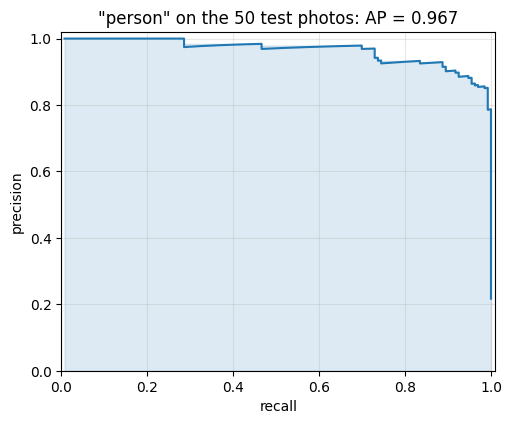

In [12]:
def average_precision(rows, n_true):
    hits = np.cumsum([hit for score, hit in rows])
    recall = hits / n_true
    precision = hits / np.arange(1, len(rows) + 1)
    envelope = np.maximum.accumulate(precision[::-1])[::-1]              # best precision at this recall or beyond
    steps = np.diff(np.concatenate([[0.0], recall]))
    return float((steps * envelope).sum()), recall, precision

ap, recall, precision = average_precision(rows, n_people)
print(f'AP (IoU at least 0.5) = {ap:.3f}')
ap75 = average_precision(mark_hits(detections, truths, 0.75), n_people)[0]
print(f'AP (IoU at least 0.75) = {ap75:.3f}')
print(f'RESULT pretrained_ap50: {ap:.4f}')
print(f'RESULT pretrained_ap75: {ap75:.4f}')

plt.figure(figsize=(5.6, 4.4))
plt.plot(recall, precision, color='tab:blue')
plt.fill_between(recall, np.maximum.accumulate(precision[::-1])[::-1], alpha=0.15, color='tab:blue')
plt.xlabel('recall'); plt.ylabel('precision'); plt.xlim(0, 1.01); plt.ylim(0, 1.02)
plt.title(f'"person" on the 50 test photos: AP = {ap:.3f}')
plt.grid(alpha=0.3)
plt.show()

The detector has never seen these photos and scores an AP of about 0.97 with the usual IoU of 0.5. Asking for tighter boxes (IoU at least 0.75) lowers it. **mAP**, the number in detection papers, is this AP averaged over all the categories of a dataset. The "COCO mAP" also averages over IoU thresholds from 0.5 to 0.95.

What does it get wrong? The most confident misses are worth a look.

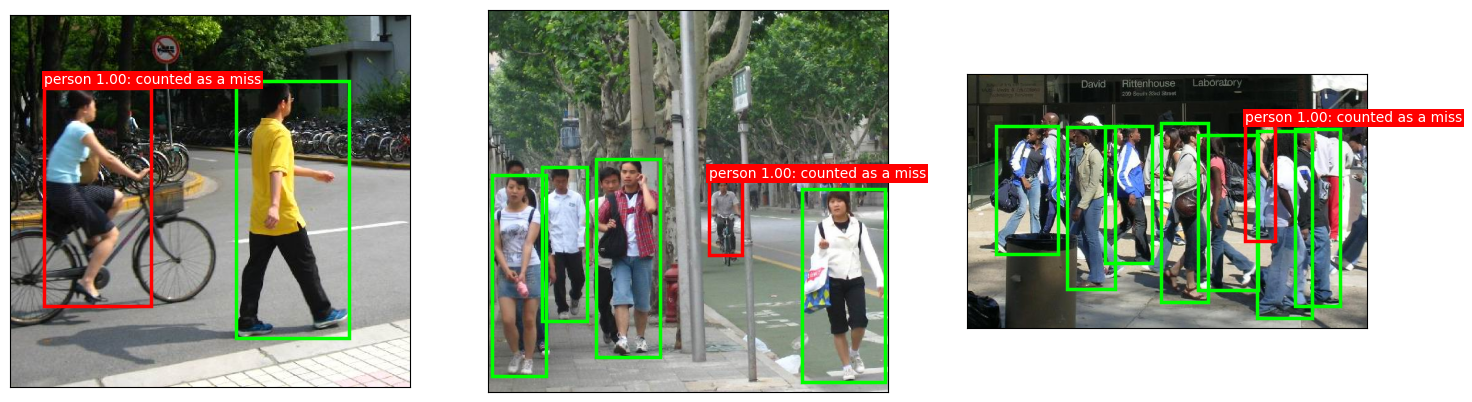

green: the dataset's boxes   red: a confident detection that matches none of them


In [13]:
worst = []
for i, (boxes, scores), truth in zip(test_idx, detections, truths):
    for score, hit, k in sorted(((s, h, k) for (s, h), k in zip(mark_hits([(boxes, scores)], [truth]), scores.argsort(descending=True).tolist())), reverse=True):
        if not hit:
            worst.append((score, i, k))
worst.sort(reverse=True)
fig, axs = plt.subplots(1, 3, figsize=(15, 4.8))
for ax, (score, i, k) in zip(axs, worst[:3]):
    ax.imshow(read_photo(i))
    draw_boxes(ax, true_boxes(i), 'lime')
    draw_boxes(ax, detections[test_idx.index(i)][0][k:k + 1], 'red', [f'person {score:.2f}: counted as a miss'])
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()
print('green: the dataset\'s boxes   red: a confident detection that matches none of them')

Look closely before blaming the detector. The dataset labels **pedestrians**: people on bicycles and some people in the background have no box, so a detector that finds them is charged with a false alarm. As in Lecture 16, the score measures agreement with somebody's labels.

## Adapting the Detector to Our Own Classes

COCO has 80 categories. A project usually has its own: here two, background and pedestrian. The recipe is Lecture 15's: keep the pretrained network, **replace the head** (the last layer, which gives one score and one box correction per category), and fine-tune with a small learning rate.

In training mode a detection model takes the images **and their true boxes**, and returns its losses instead of detections: classification and box regression for each of the two stages.

In [14]:
def pedestrian_detector():
    model = models.detection.fasterrcnn_resnet50_fpn(weights=models.detection.FasterRCNN_ResNet50_FPN_Weights.DEFAULT)
    in_features = model.roi_heads.box_predictor.cls_score.in_features          # 1024
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes=2)   # background, pedestrian
    return model.to(device)

model = pedestrian_detector()
model.train()
images = [to_tensor(read_photo(i)).to(device) for i in train_idx[:2]]
targets = [{'boxes': true_boxes(i).to(device), 'labels': torch.ones(len(true_boxes(i)), dtype=torch.long, device=device)} for i in train_idx[:2]]
losses = model(images, targets)
for name, value in losses.items():
    print(f'{name:22s} {value.item():.3f}')
print('their sum is the loss that loss.backward() starts from')

loss_classifier        0.730
loss_box_reg           0.559
loss_objectness        0.035
loss_rpn_box_reg       0.012
their sum is the loss that loss.backward() starts from


Training is the loop of every earlier notebook, with a batch of two photos and a horizontal flip that moves the boxes along with the pixels. It runs here only if a GPU is available: three epochs take about 3 minutes on a GPU and most of an hour on a laptop CPU. Without a GPU, read the printed results below.

In [15]:
FINE_TUNE = torch.cuda.is_available()          # set to True to run it on a CPU anyway

def fine_tune(model, epochs=3, lr=0.005, seed=0):
    optimizer = torch.optim.SGD([p for p in model.parameters() if p.requires_grad], lr=lr, momentum=0.9, weight_decay=5e-4)
    g = torch.Generator().manual_seed(seed)
    for epoch in range(epochs):
        model.train()
        shuffled = [train_idx[k] for k in torch.randperm(len(train_idx), generator=g).tolist()]
        total = 0.0
        for start in range(0, len(shuffled), 2):
            images, targets = [], []
            for i in shuffled[start:start + 2]:
                image, boxes = to_tensor(read_photo(i)), true_boxes(i)
                if torch.rand(1, generator=g) < 0.5:                     # flip the photo and its boxes together
                    image = image.flip(2)
                    width = image.shape[2]
                    boxes = torch.stack([width - boxes[:, 2], boxes[:, 1], width - boxes[:, 0], boxes[:, 3]], dim=1)
                images.append(image.to(device))
                targets.append({'boxes': boxes.to(device), 'labels': torch.ones(len(boxes), dtype=torch.long, device=device)})
            loss = sum(model(images, targets).values())
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total += loss.item()
        print(f'epoch {epoch + 1}: mean training loss {total / (len(shuffled) / 2):.3f}')
    return model

tuned_detections = None
if FINE_TUNE:
    torch.manual_seed(0)
    start = time.time()
    model = fine_tune(pedestrian_detector())
    tuned_detections = detect_people(model, test_idx)
    tuned_ap = average_precision(mark_hits(tuned_detections, truths), n_people)[0]
    tuned_ap75 = average_precision(mark_hits(tuned_detections, truths, 0.75), n_people)[0]
    print(f'fine-tuned:  AP (IoU 0.5) {tuned_ap:.3f}   AP (IoU 0.75) {tuned_ap75:.3f}   ({time.time() - start:.0f} s)')
    print(f'pretrained:  AP (IoU 0.5) {ap:.3f}   AP (IoU 0.75) {ap75:.3f}')
    print(f'RESULT tuned_ap50: {tuned_ap:.4f}')
    print(f'RESULT tuned_ap75: {tuned_ap75:.4f}')
    print(f'RESULT tuned_detections: {sum(len(s) for b, s in tuned_detections)}')
    print('with a score threshold of 0.5:')
    for name, dets in (('pretrained', detections), ('fine-tuned', tuned_detections)):
        kept = [hit for score, hit in mark_hits(dets, truths) if score >= 0.5]
        print(f'   {name}: {len(kept):3d} detections, {sum(kept):3d} hits, {len(kept) - sum(kept):3d} false alarms   precision {sum(kept) / len(kept):.2f}   recall {sum(kept) / n_people:.2f}')
        print(f'RESULT at05_{name.replace("-", "")}: {len(kept)} {sum(kept)}')
else:
    print('no GPU: fine-tuning skipped')

epoch 1: mean training loss 0.280


epoch 2: mean training loss 0.125


epoch 3: mean training loss 0.097


fine-tuned:  AP (IoU 0.5) 0.984   AP (IoU 0.75) 0.941   (137 s)
pretrained:  AP (IoU 0.5) 0.967   AP (IoU 0.75) 0.907
RESULT tuned_ap50: 0.9842
RESULT tuned_ap75: 0.9410
RESULT tuned_detections: 232
with a score threshold of 0.5:
   pretrained: 270 detections, 133 hits, 137 false alarms   precision 0.49   recall 1.00
RESULT at05_pretrained: 270 133
   fine-tuned: 161 detections, 131 hits,  30 false alarms   precision 0.81   recall 0.98
RESULT at05_finetuned: 161 131


The AP moves only a little, and that is the honest result: "person" is one of COCO's 80 categories, and the pretrained detector already ranked nearly every pedestrian above its false alarms. What fine-tuning changes is what the detector **counts** as an object. It has now seen 120 photos in which small, distant and half-hidden people in the background have no box, and it stops reporting most of them: at a score threshold of 0.5 the false alarms drop to a fraction, at the cost of a pedestrian or two. (The cyclist of the picture above is still reported: one of the things three epochs did not change.) It has learned the dataset's convention. For a category COCO does not have, such as a particular machine part or a species of bird, the same few lines are the difference between a detector that cannot name your object and one that can.

## From Boxes to Masks: Mask R-CNN

Lecture 16 ended with two pedestrians merged into one blob. **Mask R-CNN** is Faster R-CNN with one more head: for every detected box, a small fully convolutional network (Lecture 16's kind of network) predicts a mask **inside that box**. One object, one box, one mask: this is instance segmentation.

boxes   (15, 4)
labels  (15,)
scores  (15,)
masks   (15, 1, 317, 428)
2 people found, scores [1.0, 0.999]
RESULT mask_people: 2


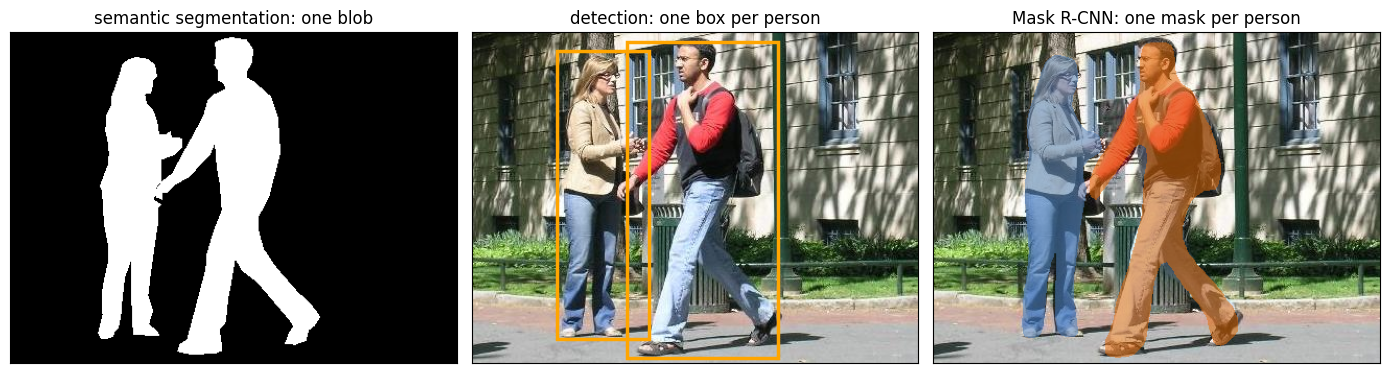

In [16]:
mask_weights = models.detection.MaskRCNN_ResNet50_FPN_Weights.DEFAULT
mask_rcnn = models.detection.maskrcnn_resnet50_fpn(weights=mask_weights).eval().to(device)
with torch.no_grad():
    out = mask_rcnn([to_tensor(read_photo(TWO)).to(device)])[0]
for key, value in out.items():
    print(f'{key:7s} {tuple(value.shape)}')
people = (out['labels'] == 1) & (out['scores'] >= 0.8)
masks = (out['masks'][people, 0] > 0.5).cpu().numpy()          # one mask per detected person, as large as the photo
print(int(people.sum()), 'people found, scores', [round(s, 3) for s in out['scores'][people].tolist()])
print(f'RESULT mask_people: {int(people.sum())}')

overlay = read_photo(TWO).copy()
for mask, color in zip(masks, ((79, 129, 189), (227, 108, 10), (47, 158, 110), (200, 128, 26))):
    overlay[mask] = (0.45 * overlay[mask] + 0.55 * np.array(color)).astype(np.uint8)
fig, axs = plt.subplots(1, 3, figsize=(14, 4.4))
axs[0].imshow(read_mask(TWO) > 0, cmap='gray'); axs[0].set_title('semantic segmentation: one blob')
axs[1].imshow(read_photo(TWO)); draw_boxes(axs[1], out['boxes'][people].cpu(), 'orange'); axs[1].set_title('detection: one box per person')
axs[2].imshow(overlay); axs[2].set_title('Mask R-CNN: one mask per person')
for ax in axs:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

In [17]:
out_dir = Path('output')
out_dir.mkdir(exist_ok=True)
save = {'test_idx': np.array(test_idx), 'two': np.array(TWO), 'crowd': np.array(CROWD), 'raw_boxes': raw_boxes.numpy(), 'raw_scores': raw_scores.numpy(),
        'mask_masks': masks, 'mask_boxes': out['boxes'][people].cpu().numpy(), 'worst': np.array([[s, i, k] for s, i, k in worst[:6]])}
for name, dets in (('pre', detections), ('tuned', tuned_detections)):
    if dets is not None:
        save[name + '_boxes'] = np.concatenate([b.numpy() for b, s in dets])
        save[name + '_scores'] = np.concatenate([s.numpy() for b, s in dets])
        save[name + '_photo'] = np.concatenate([np.full(len(s), k) for k, (b, s) in enumerate(dets)])
np.savez_compressed(out_dir / 'pedestrian_detection.npz', **save)
print('saved the detections on the test photos to', out_dir / 'pedestrian_detection.npz')

saved the detections on the test photos to output/pedestrian_detection.npz


## Try It Yourself

1. Run `detector` on a photo of your own (`to_tensor(cv.cvtColor(cv.imread(...), cv.COLOR_BGR2RGB))`). Which of COCO's categories does it find, and what does it miss?
2. Change the NMS threshold in `nms(raw_boxes, raw_scores, threshold)` to 0.3 and to 0.7 on the crowd photo. Which one loses people who stand close together, and which one leaves duplicates?
3. Compute the AP with `iou_needed=0.9`. Why does it drop so much, when the boxes look fine to the eye?
4. In `mark_hits`, allow a true box to be claimed more than once (remove the `claimed` bookkeeping). What happens to the AP, and what bad behavior would that reward?
5. Replace the detector by `models.detection.fasterrcnn_mobilenet_v3_large_fpn` with its `DEFAULT` weights: a smaller backbone. Compare its speed and its AP.
6. If you have a GPU: fine-tune for one epoch and for five. Does the AP at IoU 0.75 keep improving?
7. Count pedestrians per test photo with Mask R-CNN (masks with a score of at least 0.8) and compare with the number of labeled pedestrians. Lecture 16's blob count was right in 32 of 50 photos.